# functions

In [23]:
import numpy as np
from matplotlib import pyplot as plt
def generate_triangular_lattice(H=500, W=500, spacing=30, sigma=2.5, amplitude=1.0, center=None):
    """
    Generate a triangular lattice pattern as a 2D numpy array.

    Parameters
    ----------
    H, W : int
        Height and width of the output array.
    spacing : float
        Distance between nearest lattice points (in pixels).
    sigma : float
        Gaussian peak width (standard deviation in pixels).
    amplitude : float
        Peak height.
    center : tuple(float, float) or None
        Center of the lattice in (x, y) pixel coordinates.
        Can be fractional (subpixel precision). If None, defaults to image center.

    Returns
    -------
    data : np.ndarray
        2D numpy array of shape (H, W) with normalized values in range [0, 1].
    """
    # Lattice basis vectors (triangular symmetry)
    a1 = np.array([1.0, 0.0])
    a2 = np.array([0.5, np.sqrt(3) / 2])

    # Coordinate grid
    y = np.arange(H)
    x = np.arange(W)
    X, Y = np.meshgrid(x, y)

    # Set center
    if center is None:
        center = (W / 2, H / 2)
    center = np.array(center, dtype=float)  # allow subpixel

    # Output array
    data = np.zeros((H, W), dtype=float)

    # Number of lattice points in each direction
    n_i = int(W / spacing) + 6
    n_j = int(H / spacing) + 6

    # Generate Gaussian peaks
    for i in range(-n_i, n_i + 1):
        for j in range(-n_j, n_j + 1):
            pos = (i * a1 + j * a2) * spacing + center
            px, py = pos
            # Skip points too far outside image
            if px < -3*sigma or px > W + 3*sigma or py < -3*sigma or py > H + 3*sigma:
                continue
            rr = (X - px) ** 2 + (Y - py) ** 2
            data += amplitude * np.exp(-rr / (2 * sigma ** 2))

    # Normalize to 0..1
    data = (data - data.min()) / (data.max() - data.min())

    return data
    

In [24]:
import numpy as np

def get_angle_vector(angle_deg):
    theta = np.radians(angle_deg)
    return np.array([np.cos(theta), np.sin(theta)])
cs = get_angle_vector


r3 = np.sqrt(3)
H=500 
W=500
spacing=30
sigma=15
posYinYangs = np.array(((0,0),
                        r3*30*cs(30)))
shifts = 15*r3*np.array((
    cs(210),
    cs(330),
    cs(90)
))*0.8


def base_lattice():
    img = np.zeros((H,W))
    img += generate_triangular_lattice(H=H, W=W, spacing=spacing, sigma=sigma, center= (spacing/r3)*cs(30))
    img -= generate_triangular_lattice(H=H, W=W, spacing=spacing, sigma=sigma, center= (spacing/r3)*cs(-30))
    return img


def cdw(center_shift = (0,0)):
    img = np.zeros((H,W))
    for iyy in range(2):
        posYinYang = posYinYangs[iyy] 
        for ishift in range(3):
            shift = shifts[ishift]
            center = posYinYang + shift * (-2*iyy+1) + center_shift #+ 30*cs(120)*i4             
            corrugation_now = generate_triangular_lattice(H=H, W=W, spacing=spacing*3, sigma=sigma,  center=center)*.5
            img += corrugation_now* (-2*iyy+1)
    return img
# img = base_lattice() + (cdw(0)+ cdw(30*cs(0))+ cdw(30*cs(-60)))/2


# plt.imshow(img,cmap= 'viridis',vmax=img.max(),vmin=img.min())
# plt.plot(240,240,'ro')

In [115]:
a1 = 30*cs(0)
a2 = 30*cs(-60)
offset=2*90*cs(60) + a1*6 +(-3)*a2
def ref_cntr():
    cp.Collection.Generator.gen_regular_polygon(3,
    x=offset[0],
    y=offset[1],
    r=30*r3,
    alpha=.5,
    phi=np.pi/2,
    c='w')

# data synth

In [ ]:

ground9 = np.zeros((500,500,3,3))
for ii in range(3):
    for jj in range(3):
        cntr = (ii-1)*a1 + (jj-1)*a2
        ground9[:,:,ii,jj] =  cdw(cntr)


In [83]:
# fig,axs = plt.subplots(2,2)
bl = base_lattice()
c1 = ground9[:,:,1,1]#cdw(0)
c2 = ground9[:,:,2,1]#cdw(30*cs(0))
c3 = ground9[:,:,1,2]#cdw(30*cs(-60))
# img1 = bl + cdw(30*cs(0))
# img2 = bl + (cdw(30*cs(-60)))
# img3 = bl + (cdw(30*cs(0))+ cdw(30*cs(-60)))/2
# img4 = bl + (cdw(0)+ cdw(30*cs(0))+ cdw(30*cs(-60)))/3
# cmap = 'cividis'
# axs[0,0].imshow(img1,cmap=cmap)
# axs[0,1].imshow(img2,cmap=cmap)
# axs[1,0].imshow(img3,cmap=cmap)
# axs[1,1].imshow(img4,cmap=cmap)
# plt.tight_layout()
# fig.savefig('fake_stm_images.svg')



In [84]:
foo =np.zeros((500,500,4,3))
foo[:,:,0,0] = bl
foo[:,:,1,0] = c1
foo[:,:,2,0] = c2
foo[:,:,3,0] = c3
foo[:,:,0,1] = bl + c1
foo[:,:,1,1] = bl + c2
foo[:,:,2,1] = bl + c3
# foo(:,:,3,1) = c3
foo[:,:,0,2] = bl + (c1 +c2)/2
foo[:,:,1,2] = bl + (c2 +c3)/2
foo[:,:,2,2] = bl + (c3 +c1)/2
# foo(:,:,3,1) = c3

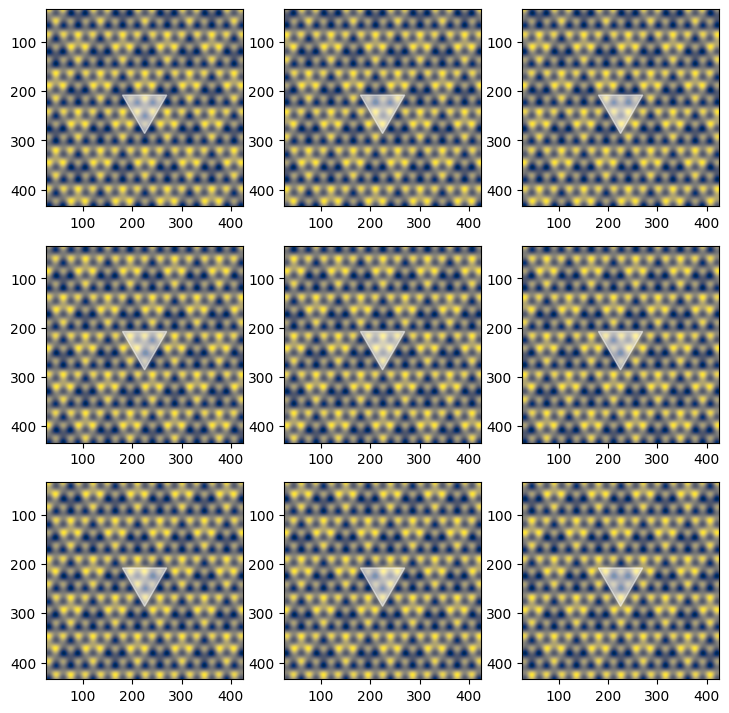

In [116]:
nrows, ncols = 3, 3           # 4행 3열 패널
panel_size = 2.5              # 각 정사각형 패널의 한 변 크기 (인치)
wspace, hspace = 0.1, 0.1     # 패널 간 가로, 세로 간격 (인치)
margin_x, margin_y = 1.0, 1.0 # 전체 도화지의 좌우, 상하 총 여백

# 2. 전체 Figure 크기(figsize) 역계산
fig_width = (ncols * panel_size) + ((ncols - 1) * wspace) + margin_x
fig_height = (nrows * panel_size) + ((nrows - 1) * hspace) + margin_y

# 3. 계산된 figsize로 subplots 생성
fig, axes = plt.subplots(nrows, ncols, figsize=(fig_width, fig_height))
for irow in range(nrows):
    for icol in range(ncols):
        ax = axes[irow,icol]
        plt.sca(ax)
        img = ground9[:,:,icol,irow]+bl
        ax.imshow(img,cmap='cividis')
        # ax.axhline(offset[1])
        # ax.axvline(offset[0])
        ax.set_xlim(offset[0]+np.array((-200,200)))
        ax.set_ylim(offset[1]+np.array((200,-200)))
        ref_cntr()

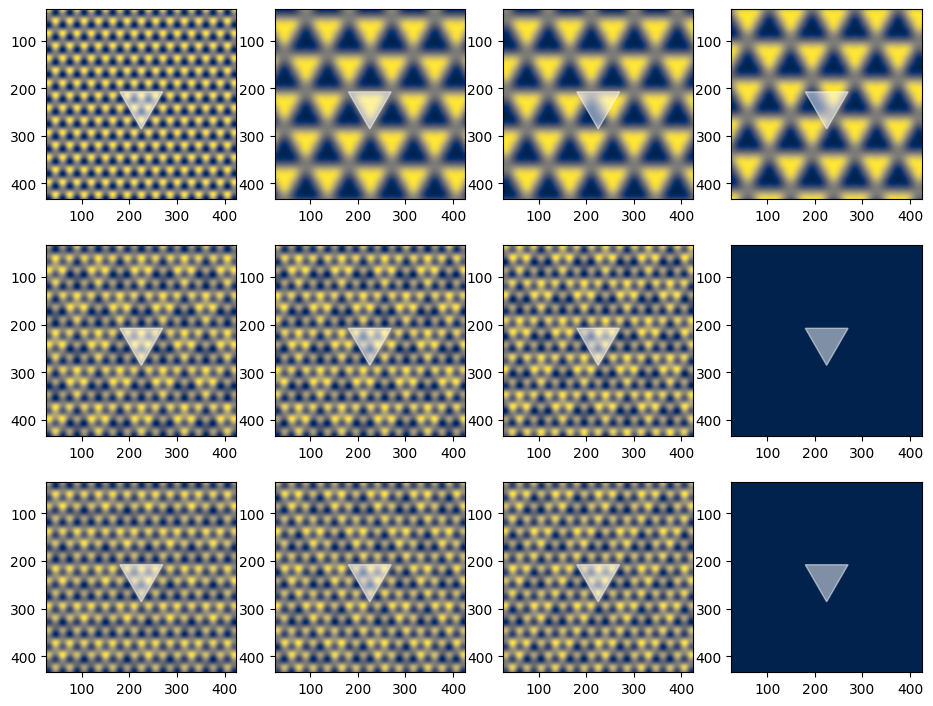

In [111]:
import matplotlib.pyplot as plt

# 1. 원하는 조건 설정 (인치 단위)
nrows, ncols = 3, 4           # 4행 3열 패널
panel_size = 2.5              # 각 정사각형 패널의 한 변 크기 (인치)
wspace, hspace = 0.1, 0.1     # 패널 간 가로, 세로 간격 (인치)
margin_x, margin_y = 1.0, 1.0 # 전체 도화지의 좌우, 상하 총 여백

# 2. 전체 Figure 크기(figsize) 역계산
fig_width = (ncols * panel_size) + ((ncols - 1) * wspace) + margin_x
fig_height = (nrows * panel_size) + ((nrows - 1) * hspace) + margin_y

# 3. 계산된 figsize로 subplots 생성
fig, axes = plt.subplots(nrows, ncols, figsize=(fig_width, fig_height))

# 4. 각 패널이 물리적으로 완벽한 정사각형(1:1 비율)이 되도록 설정
# for ax in axes.flat:
#     ax.set_box_aspect(1)
for irow in range(nrows):
    for icol in range(ncols):
        ax = axes[irow,icol]
        plt.sca(ax)
        img = foo[:,:,icol,irow]
        ax.imshow(img,cmap='cividis')
        # ax.axhline(offset[1])
        # ax.axvline(offset[0])
        ax.set_xlim(offset[0]+np.array((-200,200)))
        ax.set_ylim(offset[1]+np.array((200,-200)))
        
        cp.Collection.Generator.gen_regular_polygon(3,
        x=offset[0],
        y=offset[1],
        r=30*r3,
        alpha=.5,
        phi=np.pi/2,
        c='w')

# plt.show()

In [41]:
img

array([[ 0.28831472,  0.3245059 ,  0.36012106, ..., -0.18813053,
        -0.20103954, -0.21237662],
       [ 0.26404754,  0.30195088,  0.34317726, ..., -0.04174944,
        -0.06450963, -0.08899641],
       [ 0.23653123,  0.27601438,  0.32266118, ...,  0.09958892,
         0.06708758,  0.02960563],
       ...,
       [ 0.46381001,  0.46086373,  0.44424292, ..., -0.29682351,
        -0.28150332, -0.25495081],
       [ 0.5832858 ,  0.57724431,  0.55405592, ..., -0.31187894,
        -0.28748501, -0.24897837],
       [ 0.67619362,  0.66720062,  0.63783206, ..., -0.34266535,
        -0.30973445, -0.26001285]])